In [2]:
import os
import glob
import numpy as np 
import pandas as pd

from scipy.io import arff

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, log_loss, confusion_matrix, classification_report
)

RANDOM_STATE = 42

#loading of dataset
path = r"C:\Users\Ened Lame\Desktop\cbs\qunatitative risk management\dataset_"

#save the dataset into a dataframe for easier analysis
data, meta = arff.loadarff(path)
dataset = pd.DataFrame(data)

# print(dataset)

# target, groups, and features

target_col = "rating"
group_col = "spid"

y = dataset[target_col].astype(str)
groups = dataset[group_col].astype(str)

# drop the target and the group from the features
X = dataset.drop(columns=[target_col, group_col])

X = X.apply(pd.to_numeric, errors="raise")

# beginning of train/test split

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("\nTrain size:", X_train.shape, "Test size:", X_test.shape)
print("Unique groups train:", groups_train.nunique(), "test:", groups.iloc[test_idx].nunique())

# models

logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        max_iter=5000,
        C=1.0,
        n_jobs=None
    ))
])

hgb = HistGradientBoostingClassifier(
    loss="log_loss",
    learning_rate=0.05,
    max_depth=6,
    max_iter=500,
    random_state=RANDOM_STATE
)

models = {
    "MultinomialLogReg": logreg,
    "HistGradientBoosting": hgb
}

cv = GroupKFold(n_splits=5)

scoring = {
    "acc": "accuracy",
    "macro_f1": "f1_macro",
    "neg_log_loss": "neg_log_loss"  # higher is better (less negative)
}

cv_results = []
for name, model in models.items():
    res = cross_validate(
        model,
        X_train, y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )
    cv_results.append({
        "model": name,
        "cv_acc_mean": np.mean(res["test_acc"]),
        "cv_acc_std": np.std(res["test_acc"]),
        "cv_macro_f1_mean": np.mean(res["test_macro_f1"]),
        "cv_macro_f1_std": np.std(res["test_macro_f1"]),
        "cv_log_loss_mean": -np.mean(res["test_neg_log_loss"]),  # convert back to positive log loss
        "cv_log_loss_std": np.std(-res["test_neg_log_loss"])
    })




Train size: (3996, 6) Test size: (1004, 6)
Unique groups train: 3975 test: 994


In [ ]:
cv_df = pd.DataFrame(cv_results).sort_values(by="cv_macro_f1_mean", ascending=False)
print("\nGroupKFold CV results (train set only)")
print(cv_df.to_string(index=False))

# fit best model on full train, evaluate on held-out test 

best_model_name = cv_df.iloc[0]["model"]
best_model = models[best_model_name]
best_model.fit(X_train, y_train)

# predictions

y_pred = best_model.predict(X_test)

# probabilities (for log loss)

if hasattr(best_model, "predict_proba"):
    y_proba = best_model.predict_proba(X_test)
    test_logloss = log_loss(y_test, y_proba, labels=best_model.classes_)
else:
    y_proba = None
    test_logloss = np.nan

test_acc = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"\nHold-out test performance (GroupShuffleSplit)")
print("Best model:", best_model_name)
print(f"Accuracy     : {test_acc}")
print(f"Macro F1     : {test_macro_f1}")
print(f"Log Loss     : {test_logloss}")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

print("\nConfusion matrix (rows=true, cols=pred):")
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels])
print(cm_df)



GroupKFold CV results (train set only)
               model  cv_acc_mean  cv_acc_std  cv_macro_f1_mean  cv_macro_f1_std  cv_log_loss_mean  cv_log_loss_std
HistGradientBoosting     0.793046    0.010517          0.794571         0.009112          0.912972         0.048434
   MultinomialLogReg     0.570822    0.014569          0.567258         0.014329          1.152207         0.027471

Hold-out test performance (GroupShuffleSplit)
Best model: HistGradientBoosting
Accuracy     : 0.8247011952191236
Macro F1     : 0.8190096524363696
Log Loss     : 0.6909389560928367

Classification report:
               precision    recall  f1-score   support

above_average       0.98      0.90      0.94       112
      average       0.86      0.71      0.78       108
          bad       0.88      0.94      0.91       106
below_average       0.76      0.68      0.72       101
    excellent       0.65      0.72      0.68        95
         good       0.62      0.63      0.63        84
  outstanding       

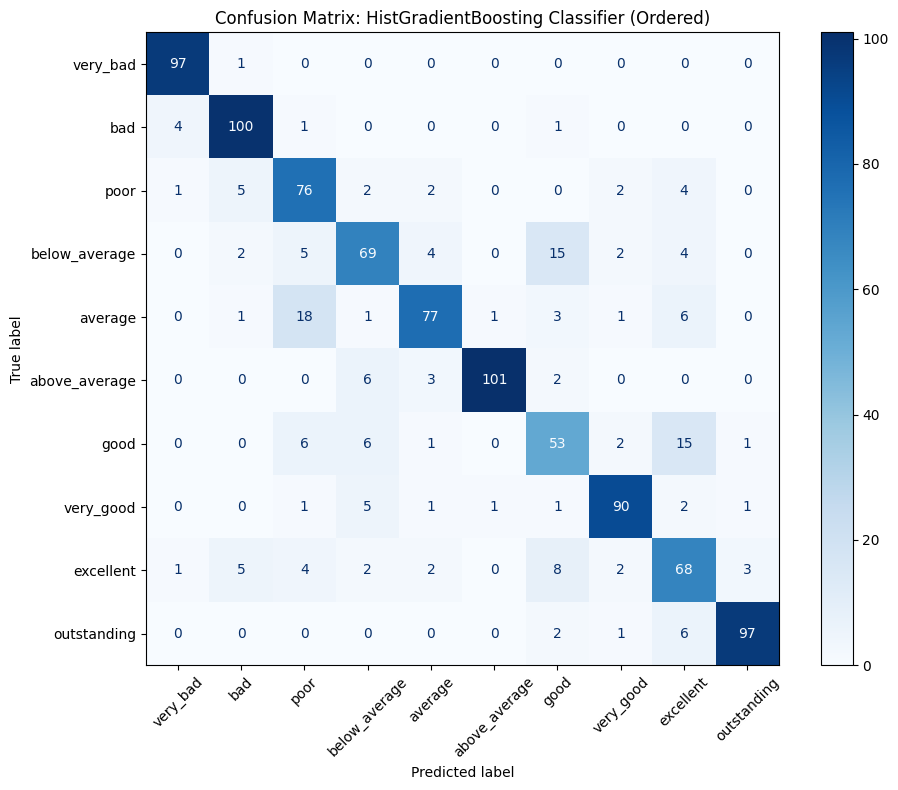

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

rating_order = [
    'very_bad', 'bad', 'poor', 'below_average', 'average', 
    'above_average', 'good', 'very_good', 'excellent', 'outstanding'
]


fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    labels=rating_order, 
    cmap='Blues', 
    ax=ax,
    xticks_rotation=45
)

plt.title("Confusion Matrix: HistGradientBoosting Classifier (Ordered)")
plt.tight_layout()
plt.show()